# **DATA PREPARATION / EXPLORATORY DATA ANALYSIS**

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("/content/healthcare_patient_data/healthcare_patient_data.csv")  # Load dataset from CSV
df.head() #printing the first 5 rows the data

,patient_id,age_group,gender,region,department,treatment_type,visit_type,length_of_stay_days,treatment_cost,recovery_score,readmission_risk
0,1,31-45,Male,West,General Medicine,Medication,Emergency,5.8,59151,59,0.12
1,2,60+,Female,West,Orthopedics,Surgery,Routine,5.1,30272,97,0.11
2,3,46-60,Male,South,Pediatrics,Observation,Routine,7.9,67498,60,0.19
3,4,31-45,Female,North,Neurology,Medication,Routine,5.0,29896,51,0.47
4,5,18-30,Female,North,Neurology,Therapy,Routine,0.0,36208,60,0.40


In [ ]:
df = df.info()  #checking the datatypes
print(df)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           5000 non-null   int64  
 1   age_group            5000 non-null   object 
 2   gender               5000 non-null   object 
 3   region               5000 non-null   object 
 4   department           5000 non-null   object 
 5   treatment_type       5000 non-null   object 
 6   visit_type           5000 non-null   object 
 7   length_of_stay_days  5000 non-null   float64
 8   treatment_cost       5000 non-null   int64  
 9   recovery_score       5000 non-null   int64  
 10  readmission_risk     5000 non-null   float64
dtypes: float64(2), int64(3), object(6)
memory usage: 429.8+ KB
None


In [ ]:
import pandas as pd
df = pd.read_csv("/content/healthcare_patient_data/healthcare_patient_data.csv")
df.describe()


,patient_id,length_of_stay_days,treatment_cost,recovery_score,readmission_risk
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,4.059660,54915.471800,74.718800,0.280966
std,1443.520003,1.928847,19481.160487,11.870481,0.157178
min,1.000000,0.000000,746.000000,33.000000,0.010000
25%,1250.750000,2.700000,41244.750000,67.000000,0.160000
50%,2500.500000,4.000000,55123.500000,75.000000,0.260000
75%,3750.250000,5.400000,68012.000000,83.000000,0.380000
max,5000.000000,11.900000,119307.000000,100.000000,0.840000


In [ ]:
df.isnull().sum() #checking if there are null values

,0
patient_id,0
age_group,0
gender,0
region,0
department,0
treatment_type,0
visit_type,0
length_of_stay_days,0
treatment_cost,0
recovery_score,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df["age_group"].value_counts()

,count
age_group,
31-45,1716
18-30,1283
46-60,1271
60+,730


In [ ]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- age_group ---
age_group
31-45    1716
18-30    1283
46-60    1271
60+       730
Name: count, dtype: int64

--- gender ---
gender
Male      2508
Female    2492
Name: count, dtype: int64

--- region ---
region
West     1290
North    1282
East     1217
South    1211
Name: count, dtype: int64

--- department ---
department
Orthopedics         1058
Cardiology           995
General Medicine     991
Pediatrics           989
Neurology            967
Name: count, dtype: int64

--- treatment_type ---
treatment_type
Observation    1270
Surgery        1262
Medication     1236
Therapy        1232
Name: count, dtype: int64

--- visit_type ---
visit_type
Routine      3432
Emergency    1568
Name: count, dtype: int64


In [ ]:
categorical_columns = [
    "age_group",
    "gender",
    "region",
    "department",
    "treatment_type",
    "visit_type"
]

for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(normalize=True) * 100) #percentage of the categorical column


--- age_group ---
age_group
31-45    34.32
18-30    25.66
46-60    25.42
60+      14.60
Name: proportion, dtype: float64

--- gender ---
gender
Male      50.16
Female    49.84
Name: proportion, dtype: float64

--- region ---
region
West     25.80
North    25.64
East     24.34
South    24.22
Name: proportion, dtype: float64

--- department ---
department
Orthopedics         21.16
Cardiology          19.90
General Medicine    19.82
Pediatrics          19.78
Neurology           19.34
Name: proportion, dtype: float64

--- treatment_type ---
treatment_type
Observation    25.40
Surgery        25.24
Medication     24.72
Therapy        24.64
Name: proportion, dtype: float64

--- visit_type ---
visit_type
Routine      68.64
Emergency    31.36
Name: proportion, dtype: float64


In [ ]:
numerical_columns = [               #maximum values of numerical columns
    "length_of_stay_days",
    "treatment_cost",
    "recovery_score",
    "readmission_risk"
]

for num_col in numerical_columns:
  print(f"\n--- {num_col} ---")
  print(df[num_col].max())


--- length_of_stay_days ---
11.9

--- treatment_cost ---
119307

--- recovery_score ---
100

--- readmission_risk ---
0.84


In [ ]:
numerical_columns = [                  #minimum values of numerical columns
    "length_of_stay_days",
    "treatment_cost",
    "recovery_score",
    "readmission_risk"
]

for num_col in numerical_columns:
  print(f"\n--- {num_col} ---")
  print(df[num_col].min())


--- length_of_stay_days ---
0.0

--- treatment_cost ---
746

--- recovery_score ---
33

--- readmission_risk ---
0.01


# **DATA VISUALIZATION**

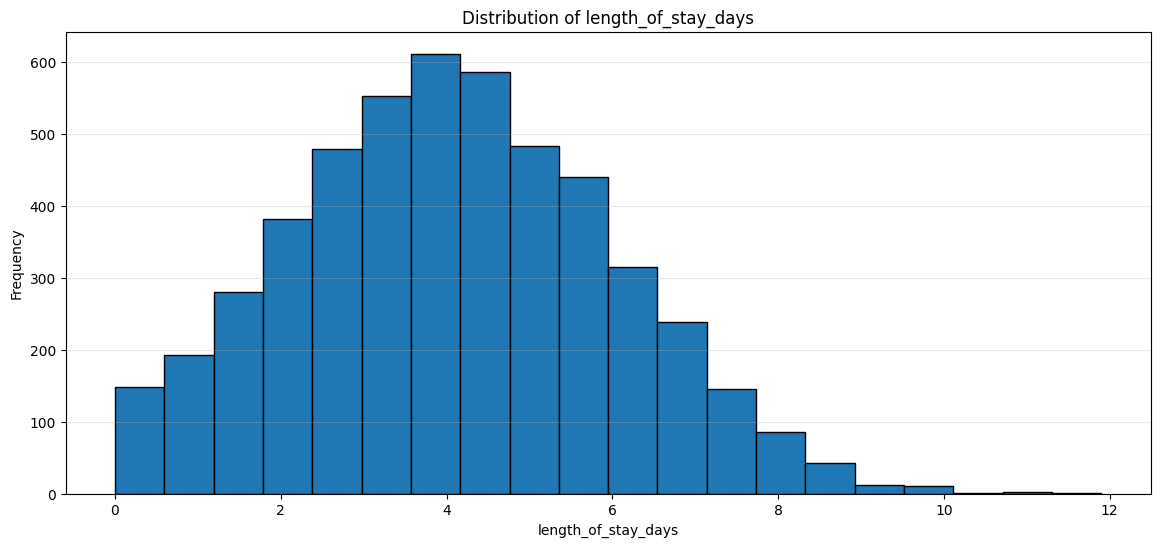

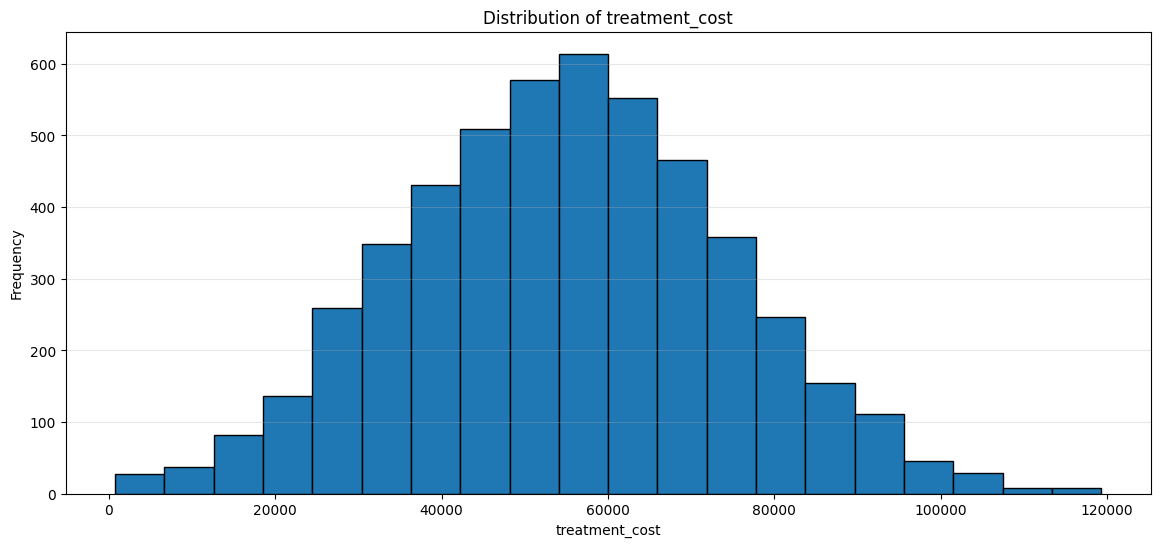

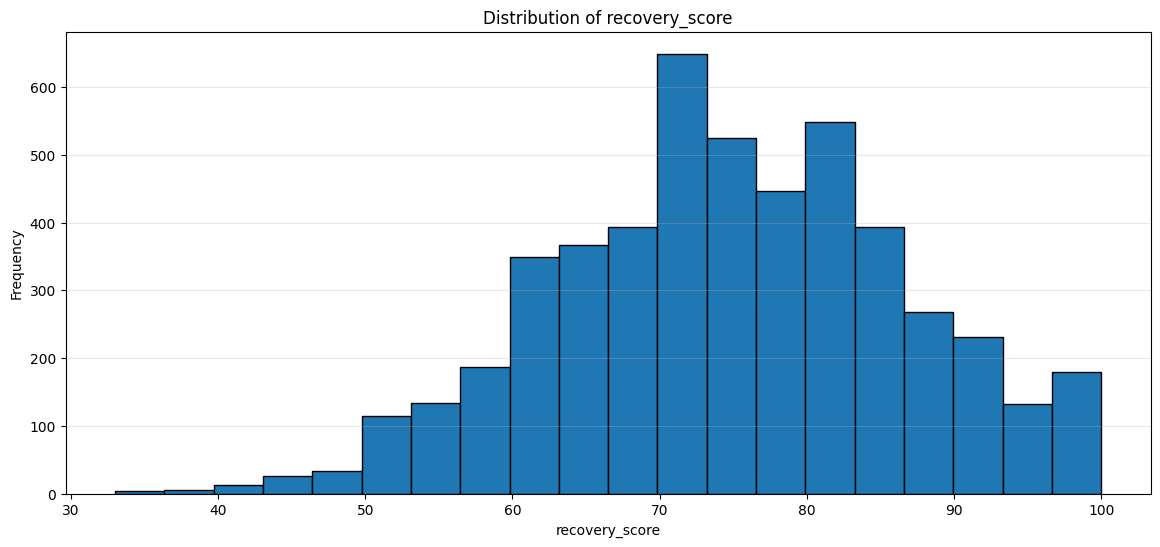

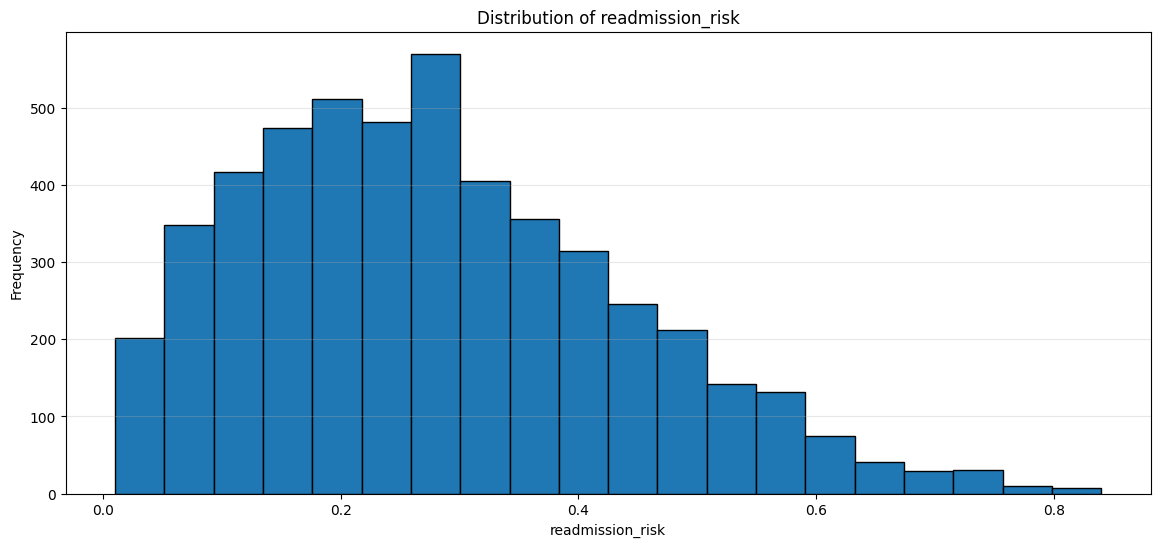

In [ ]:
numerical_columns = [
    "length_of_stay_days",
    "treatment_cost",
    "recovery_score",
    "readmission_risk"
]

for col in numerical_columns:
    plt.figure(figsize=(14, 6))

    plt.hist(df[col], bins=20, edgecolor="black")

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.grid(axis="y", alpha=0.3)
    plt.show()

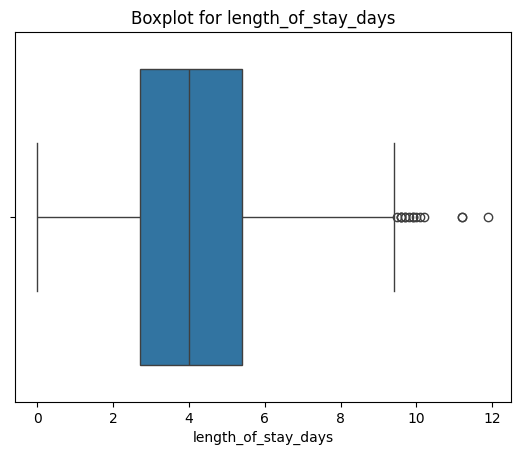

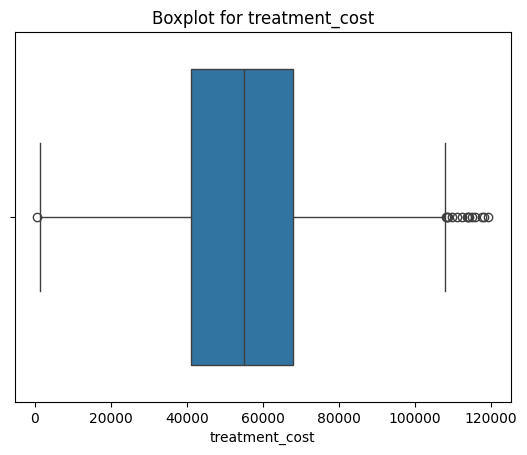

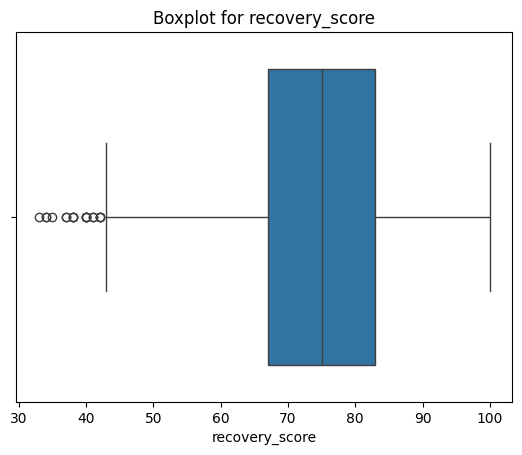

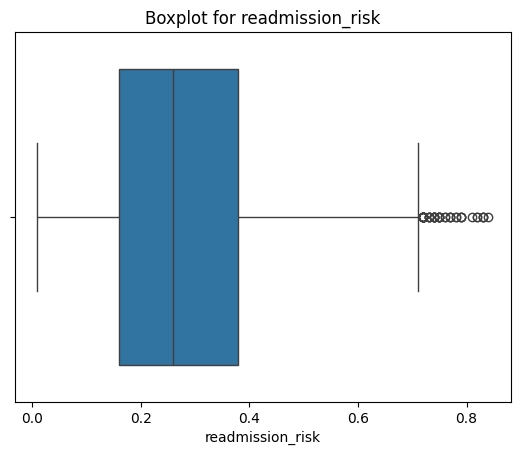

In [ ]:
numerical_columns = [
    "length_of_stay_days",
    "treatment_cost",
    "recovery_score",
    "readmission_risk"
]

for num_col in numerical_columns:
  sns.boxplot(data=df, x=num_col)
  plt.title(f'Boxplot for {num_col}')
  plt.show()

In [ ]:
# Detecting outliers using IQR method
# Compute Q1, Q3, IQR
Q1 = df['length_of_stay_days'].quantile(0.25)
Q3 = df['length_of_stay_days'].quantile(0.75)
IQR = Q3 - Q1

# Determine bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

Q1: 2.7, Q3: 5.4, IQR: 2.7
Lower Bound: -1.3500000000000005, Upper Bound: 9.450000000000001


In [ ]:
# Detecting outliers using IQR method
# Compute Q1, Q3, IQR
Q1 = df['treatment_cost'].quantile(0.25)
Q3 = df['treatment_cost'].quantile(0.75)
IQR = Q3 - Q1

# Determine bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

Q1: 41244.75, Q3: 68012.0, IQR: 26767.25
Lower Bound: 1093.875, Upper Bound: 108162.875


In [ ]:
# Detecting outliers using IQR method
# Compute Q1, Q3, IQR
Q1 = df['recovery_score'].quantile(0.25)
Q3 = df['recovery_score'].quantile(0.75)
IQR = Q3 - Q1

# Determine bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

Q1: 67.0, Q3: 83.0, IQR: 16.0
Lower Bound: 43.0, Upper Bound: 107.0


In [ ]:
# Detecting outliers using IQR method
# Compute Q1, Q3, IQR
Q1 = df['readmission_risk'].quantile(0.25)
Q3 = df['readmission_risk'].quantile(0.75)
IQR = Q3 - Q1

# Determine bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print(f"Q1: {Q1}, Q3: {Q3}, IQR: {IQR}")
print(f"Lower Bound: {lower_bound}, Upper Bound: {upper_bound}")

Q1: 0.16, Q3: 0.38, IQR: 0.22
Lower Bound: -0.17, Upper Bound: 0.71


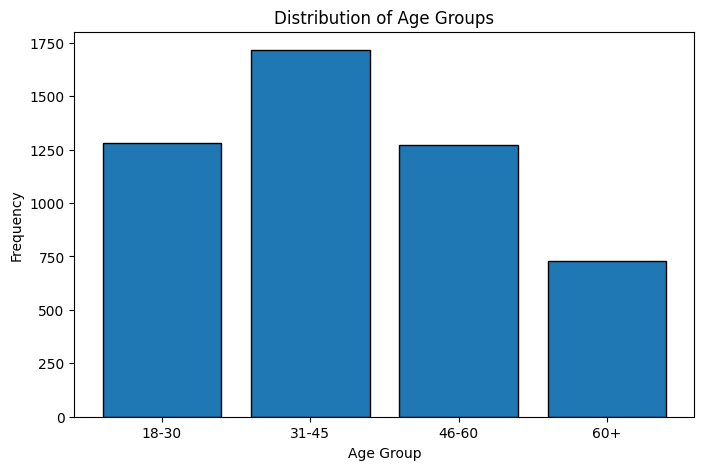

In [ ]:
age_order = ["18-30", "31-45", "46-60", "60+"]

age_counts = df["age_group"].value_counts().reindex(age_order)

plt.figure(figsize=(8, 5))
plt.bar(age_counts.index, age_counts.values, edgecolor="black")

plt.title("Distribution of Age Groups")
plt.xlabel("Age Group")
plt.ylabel("Frequency")

plt.show()

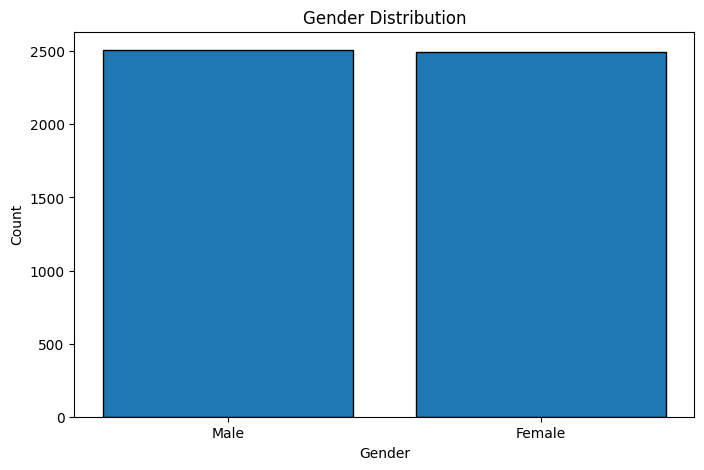

In [ ]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(gender_counts.index, gender_counts.values, edgecolor="black")

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

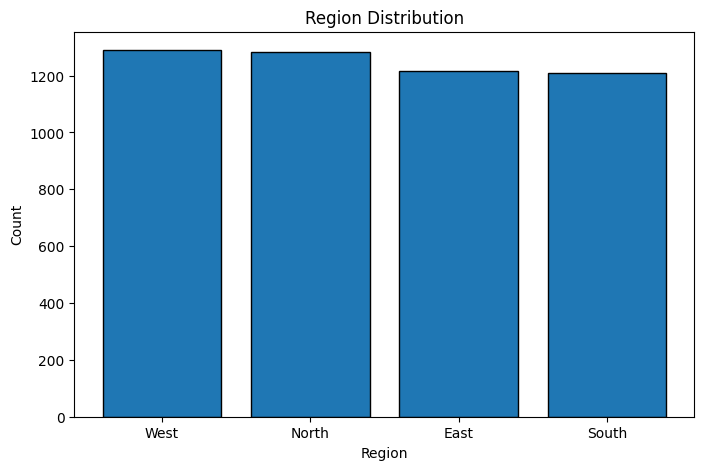

In [ ]:
region_counts = df["region"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(region_counts.index, region_counts.values, edgecolor="black")

plt.title("Region Distribution")
plt.xlabel("Region")
plt.ylabel("Count")
plt.show()

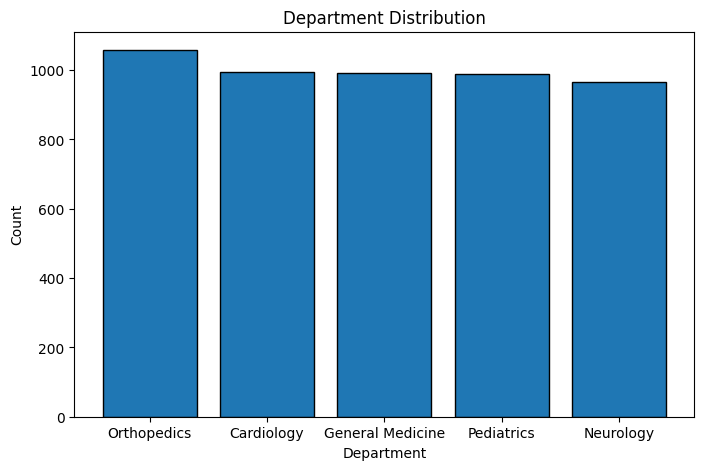

In [ ]:
department_counts = df["department"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(department_counts.index, department_counts.values, edgecolor="black")

plt.title("Department Distribution")
plt.xlabel("Department")
plt.ylabel("Count")
plt.show()

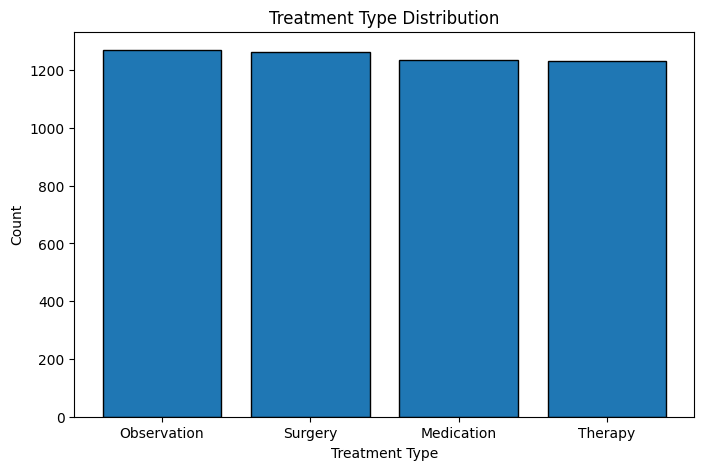

In [ ]:
treatment_type_counts = df["treatment_type"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(treatment_type_counts.index, treatment_type_counts.values, edgecolor="black")

plt.title("Treatment Type Distribution")
plt.xlabel("Treatment Type")
plt.ylabel("Count")
plt.show()

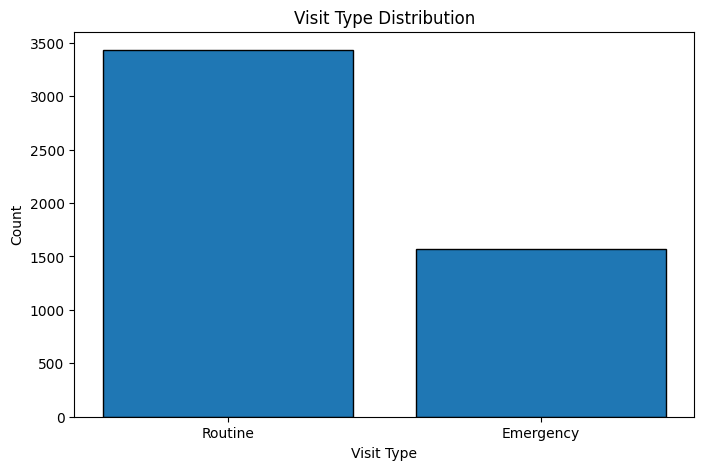

In [ ]:
visit_type_counts = df["visit_type"].value_counts().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
plt.bar(visit_type_counts.index, visit_type_counts.values, edgecolor="black")

plt.title("Visit Type Distribution")
plt.xlabel("Visit Type")
plt.ylabel("Count")
plt.show()

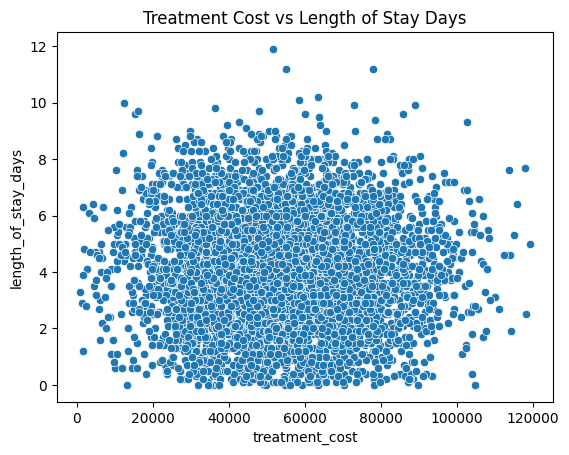

In [ ]:
sns.scatterplot(
    data=df,
    x="treatment_cost",
    y="length_of_stay_days"
)

plt.title("Treatment Cost vs Length of Stay Days")
plt.show()

In [ ]:
correlation = df["treatment_cost"].corr(df["length_of_stay_days"])

print("Correlation:", correlation)               #since it is close to zero even tho it's negative, there's no correlation between two variables

Correlation: -0.022281002942894864


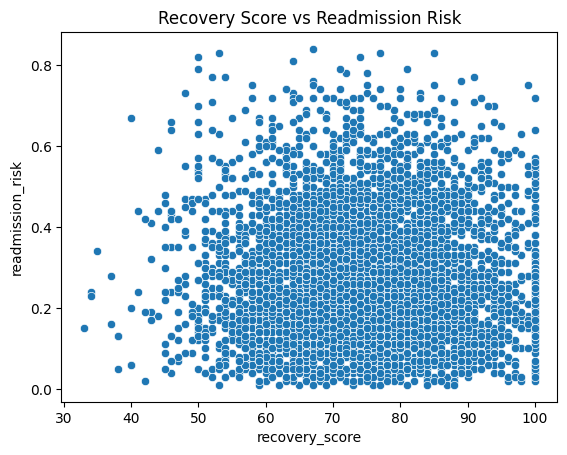

In [ ]:
sns.scatterplot(
    data=df,
    x="recovery_score",
    y="readmission_risk"
)

plt.title("Recovery Score vs Readmission Risk")
plt.show()

In [ ]:
correlation = df["recovery_score"].corr(df["readmission_risk"])

print("Correlation:", correlation)         ##since it is close to zero, there's no correlation between two variables

Correlation: 0.002051901624726886


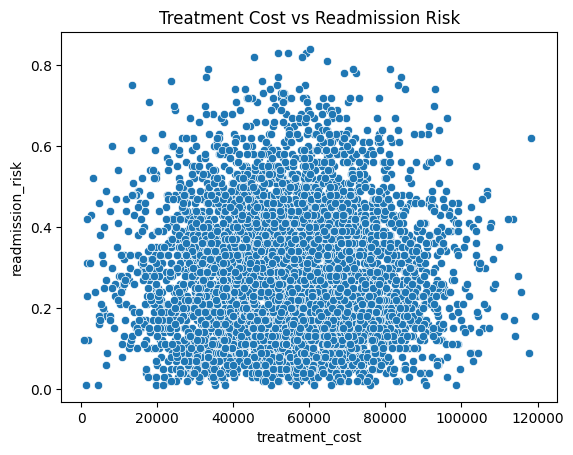

In [ ]:
sns.scatterplot(
    data=df,
    x="treatment_cost",
    y="readmission_risk"
)

plt.title("Treatment Cost vs Readmission Risk")
plt.show()

In [ ]:
correlation = df["treatment_cost"].corr(df["readmission_risk"])

print("Correlation:", correlation)       #since it is close to zero, there's no correlation between two variables

Correlation: 0.017821521084605156


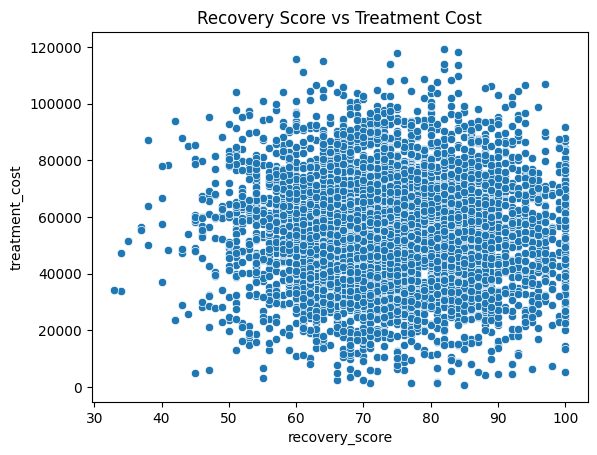

In [ ]:
sns.scatterplot(
    data=df,
    x="recovery_score",
    y="treatment_cost"
)

plt.title("Recovery Score vs Treatment Cost")
plt.show()

In [ ]:
correlation = df["recovery_score"].corr(df["treatment_cost"])

print("Correlation:", correlation)        #since it is close to zero even tho it's negative, there's no correlation between two variables

Correlation: -0.014561773363210108


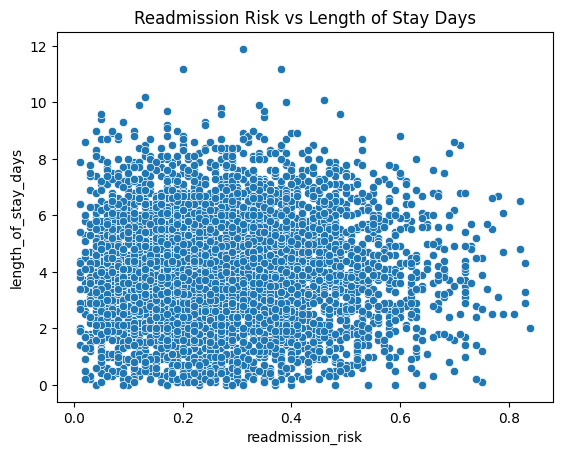

In [ ]:
sns.scatterplot(
    data=df,
    x="readmission_risk",
    y="length_of_stay_days"
)

plt.title("Readmission Risk vs Length of Stay Days")
plt.show()

In [ ]:
correlation = df["readmission_risk"].corr(df["length_of_stay_days"])

print("Correlation:", correlation)     #since it is close to zero even tho it's negative, there's no correlation between two variables

Correlation: -0.0009350703102864209


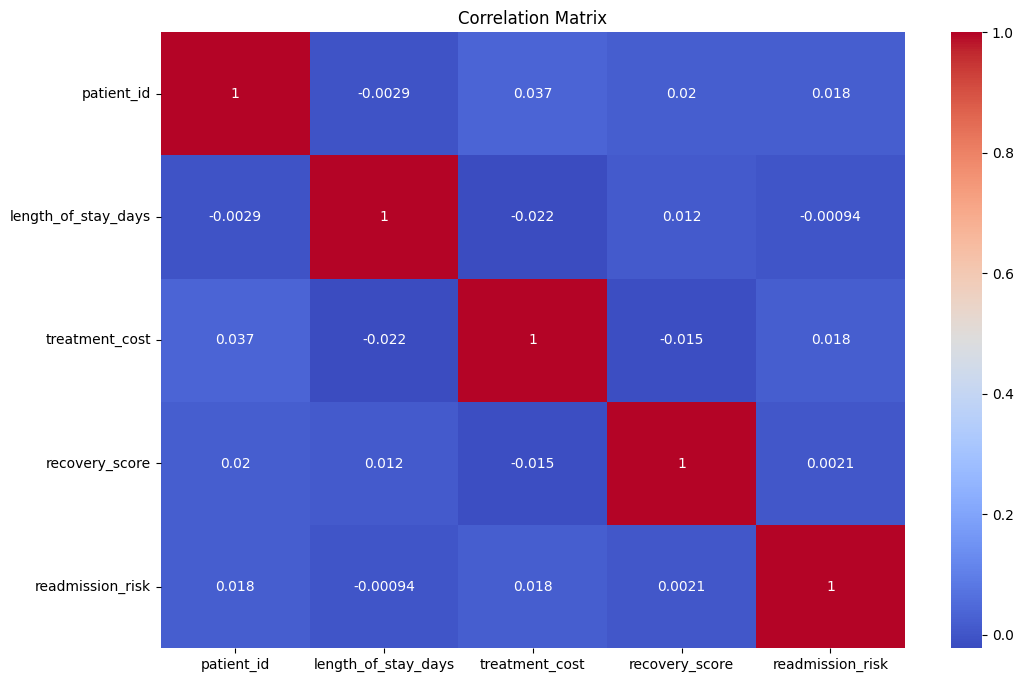

In [ ]:
corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

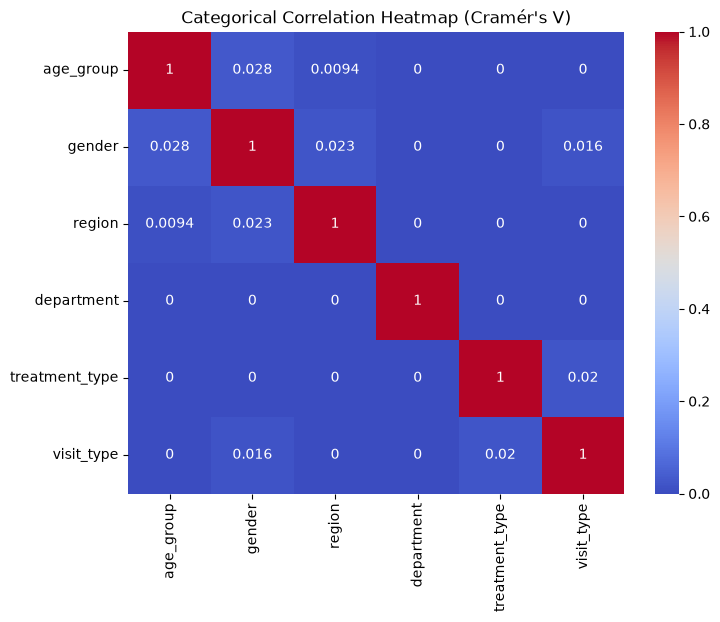

In [ ]:
import numpy as np
from scipy.stats import chi2_contingency

# Function to compute Cramér's V
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k - 1)*(r - 1)) / (n - 1))
    rcorr = r - ((r - 1)**2) / (n - 1)
    kcorr = k - ((k - 1)**2) / (n - 1)
    return np.sqrt(phi2corr / min((kcorr - 1), (rcorr - 1)))

# Select your categorical columns
categorical_cols = [
    'age_group',
    'gender',
    'region',
    'department',
    'treatment_type',
    'visit_type'
]

# Compute correlation matrix
cramers_results = pd.DataFrame(index=categorical_cols, columns=categorical_cols)

for col1 in categorical_cols:
    for col2 in categorical_cols:
        cramers_results.loc[col1, col2] = cramers_v(df[col1], df[col2])

cramers_results = cramers_results.astype(float)

# Plot heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(cramers_results, annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title("Categorical Correlation Heatmap (Cramér's V)")
plt.show()

In [ ]:
!pip install dython

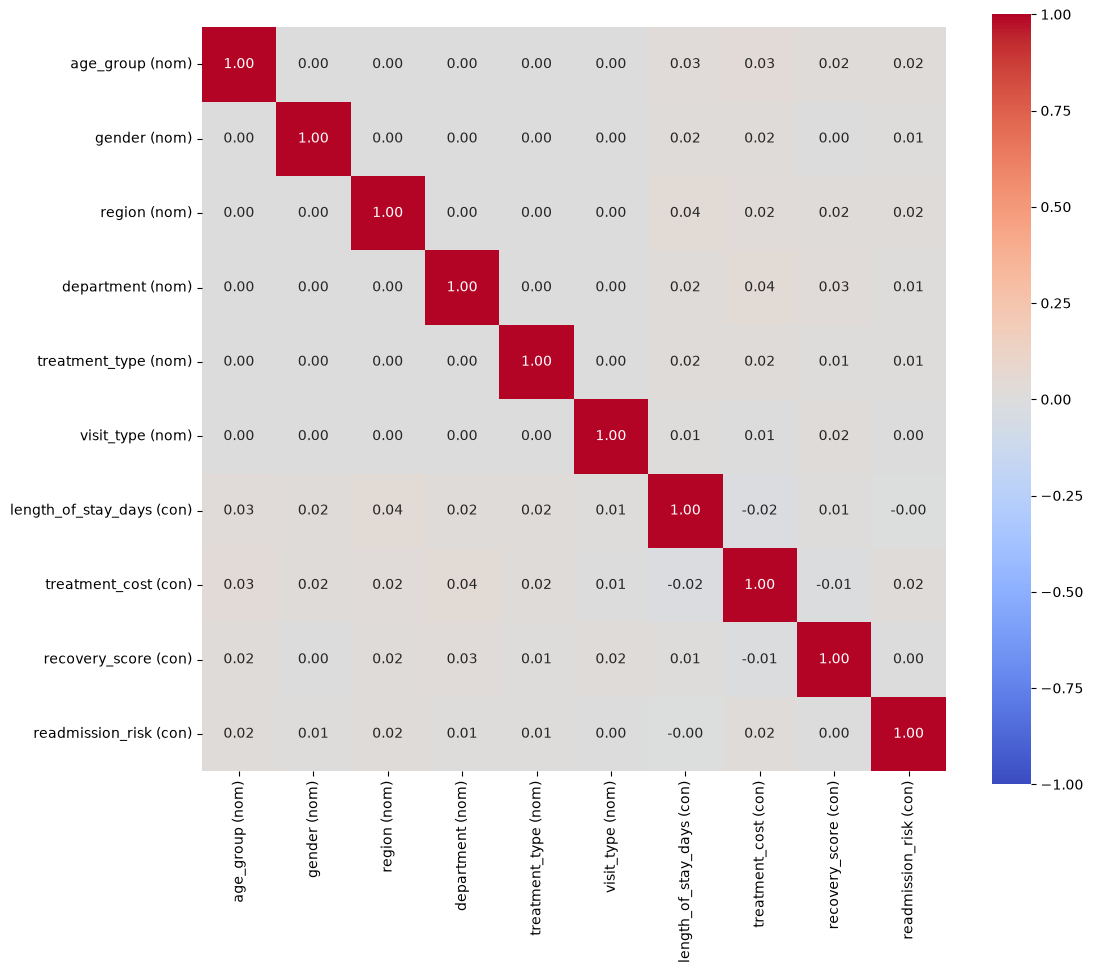

{'corr':                            age_group (nom)  gender (nom)  region (nom)  \
 age_group (nom)                   1.000000      0.000522      0.000755   
 gender (nom)                      0.001014      1.000000      0.000803   
 region (nom)                      0.000733      0.000401      1.000000   
 department (nom)                  0.000510      0.000082      0.000637   
 treatment_type (nom)              0.000611      0.000121      0.000556   
 visit_type (nom)                  0.000355      0.000389      0.000323   
 length_of_stay_days (con)         0.029151      0.019324      0.040095   
 treatment_cost (con)              0.032300      0.015906      0.024658   
 recovery_score (con)              0.019566      0.004575      0.017530   
 readmission_risk (con)            0.022951      0.008202      0.015927   
 
                            department (nom)  treatment_type (nom)  \
 age_group (nom)                    0.000610              0.000630   
 gender (nom)            

In [ ]:
from dython.nominal import associations

categorical_cols = ['age_group', 'gender', 'region', 'department', 'treatment_type', 'visit_type']
numeric_cols = ['length_of_stay_days', 'treatment_cost', 'recovery_score', 'readmission_risk']

# ✅ Keep only the columns you want
df_subset = df[categorical_cols + numeric_cols]

# Then compute associations only on that subset
associations(
    df_subset,
    nominal_columns=categorical_cols,
    numerical_columns=numeric_cols,
    nom_nom_assoc='theil',
    num_num_assoc='pearson',
    nom_num_assoc='correlation_ratio',
    mark_columns=True,
    figsize=(12, 10),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    plot=True
)

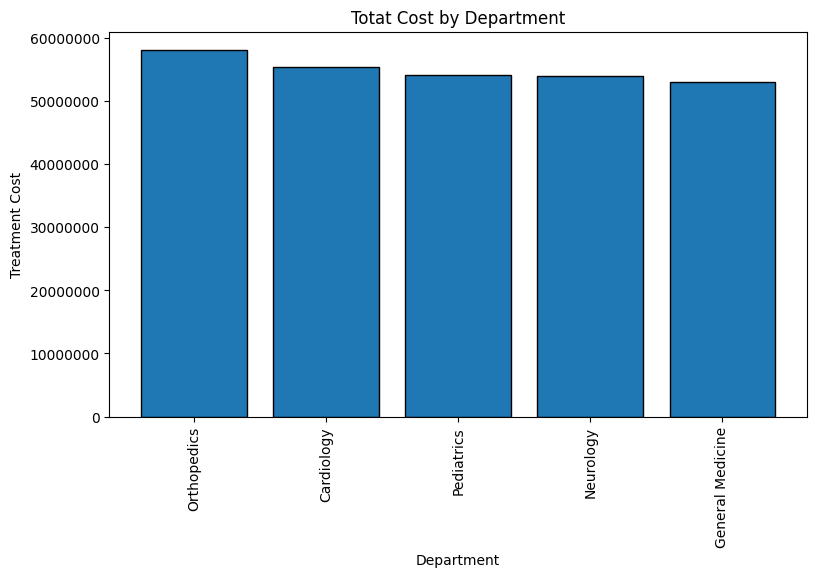

In [ ]:
groupby_department = df.groupby("department")["treatment_cost"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(groupby_department.index, groupby_department.values, edgecolor="black")


plt.title('Totat Cost by Department')
plt.xlabel('Department')
plt.ylabel('Treatment Cost')
plt.ticklabel_format(style='plain', axis='y')
plt.xticks(rotation=90)
plt.show()


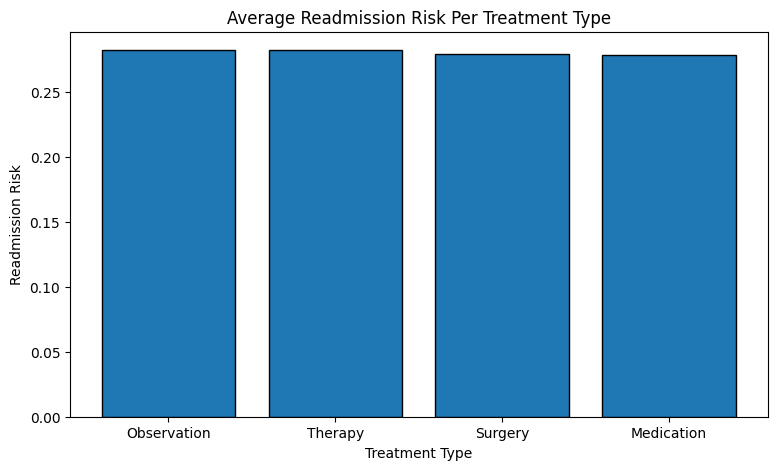

In [ ]:
groupby_treatmentType = df.groupby("treatment_type")["readmission_risk"].mean().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
plt.bar(groupby_treatmentType.index, groupby_treatmentType.values, edgecolor="black")


plt.title('Average Readmission Risk Per Treatment Type')
plt.xlabel('Treatment Type')
plt.ylabel('Readmission Risk')
plt.ticklabel_format(style='plain', axis='y')
plt.show()

In [ ]:
df.groupby("visit_type")["recovery_score"].mean().sort_values(ascending=False)


,recovery_score
visit_type,
Routine,74.886072
Emergency,74.352679


In [ ]:
df.groupby("age_group")["length_of_stay_days"].mean()

,length_of_stay_days
age_group,
18-30,4.114497
31-45,4.092483
46-60,4.020771
60+,3.953836
